# 6.3 Regression Analysis

**Goal:** fit and diagnose linear regression while separating prediction quality from inferential assumptions.

**Prerequisites:** Modules 0–4 and earlier notebooks in this module; advanced notebooks also build on earlier modules 5–8. Read the section assumptions before using a method.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. Install in your chosen environment with `python3 -m pip install numpy scipy matplotlib`, then open in JupyterLab or VS Code with a Python kernel. Use **Restart Kernel and Run All**. Each notebook is self-contained, includes saved outputs, uses synthetic data and a fixed local random seed, and needs no downloads. Numerical simulations illustrate results; they do not prove them or validate real-world assumptions.

## Module navigation

1. [Correlation](1_Correlation.ipynb)
2. [Covariance](2_Covariance.ipynb)
3. [Regression Analysis](3_Regression-Analysis.ipynb)
4. [Advanced Regression](4_Advanced-Regression.ipynb)

## Learning route

Read each definition and assumption, work through its calculation, run the code, then attempt the practice before viewing the solutions. Distinguish descriptive association, causal inference, and predictive evaluation throughout.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize, special, linalg
rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12, "font.size": 10})

## 1. Simple Linear Regression and Multiple Linear Regression

Simple regression models $Y=\beta_0+\beta_1x+\epsilon$; multiple regression uses $Y=\beta_0+\sum_j\beta_jx_j+\epsilon$. A slope is a change in conditional mean per input unit holding other modeled features fixed, not automatically a causal effect. The intercept is the modeled mean at all predictors zero, which may be outside meaningful data support.

With design matrix X including an intercept, least squares minimizes $SSE=\|y-X\beta\|²$. If full column rank holds, $\hat\beta=(X^TX)^{-1}X^Ty$, but numerical solvers should use QR/SVD least squares rather than explicitly invert XᵀX. Rank deficiency makes coefficients nonunique even when fitted values are well defined.

**Worked example:** fit price as a linear function of size and age. Parameters describe the synthetic conditional mean, not the effect of an intervention on a house.

In [2]:
n=100;size=rng.uniform(40,140,n);age=rng.uniform(0,30,n)
X=np.column_stack([np.ones(n),size,age]);y=20+3*size-.8*age+rng.normal(0,10,n)
beta=np.linalg.lstsq(X,y,rcond=None)[0];pred=X@beta;res=y-pred
print("Intercept, size slope, age slope:",beta)
print("Sum of squared errors:",res@res)

Intercept, size slope, age slope: [26.66749655  2.96741199 -1.01462905]
Sum of squared errors: 9036.12989685048


## 2. Regression Coefficients, Intercept, Residuals, and Sum of Squared Errors

A residual eᵢ=yᵢ−ŷᵢ is observed prediction error on fitted data; the model error εᵢ is an unobserved random quantity. With an intercept and ordinary full-rank least squares, residuals sum approximately to zero and are orthogonal to fitted design columns. Those algebraic properties do not prove that future errors are unbiased or independent.

Under E[ε|X]=0 and common independent error variance σ², conditional coefficient covariance is σ²(XᵀX)⁻¹. Estimating σ² by SSE/(n−p) uses p fitted coefficients including intercept. Exact small-sample t/F inference adds normal-error assumptions. Robust standard errors address some heteroscedasticity but cannot correct omitted-variable bias or dependence without a suitable design.

In [3]:
p=X.shape[1];s2=(res@res)/(n-p)
cov_beta=s2*np.linalg.inv(X.T@X)
print("Coefficient standard errors under classical model:",np.sqrt(np.diag(cov_beta)))
assert np.allclose(X.T@res,0,atol=1e-7)

Coefficient standard errors under classical model: [4.23746469 0.0377069  0.11803205]


## 3. R-squared and Adjusted R-squared

For an intercept model and nonconstant outcome, $R²=1-SSE/SST$, with $SST=\sum(y_i-\bar y)²$. Training R² does not decrease when adding ordinary least-squares predictors. Adjusted $R²=1-[SSE/(n-p)]/[SST/(n-1)]$ penalizes additional coefficients, but is not an unbiased guarantee of generalization.

Out-of-sample R² can be negative when predictions perform worse than the specified mean baseline. R² is not the fraction of outcomes predicted correctly, proof of causality, or evidence that assumptions hold. Without an intercept, familiar decompositions require care and software conventions differ.

In [4]:
sse=res@res;sst=np.sum((y-y.mean())**2)
r2=1-sse/sst;adjusted=1-(sse/(n-p))/(sst/(n-1))
print("Training R2:",r2,"adjusted R2:",adjusted)

Training R2: 0.9856965282542504 adjusted R2: 0.9854016113110391


## 4. Residual Analysis and Regression Assumptions

Check the conditional mean form (linearity in parameters with correctly specified features), exogeneity, adequate rank, and error structure appropriate to the intended inference. Normal predictors are not required. Residual-versus-fitted plots can reveal curvature, changing spread, and unusual cases; Q-Q plots assess error-shape diagnostics rather than proving normality.

**Multicollinearity** means predictors are strongly linearly related. It can inflate coefficient uncertainty and make coefficients unstable while predictions within the observed feature region remain reasonable. VIFⱼ=1/(1−Rⱼ²) quantifies an auxiliary linear relationship; no universal cutoff replaces context.

**Heteroscedasticity** means conditional error variance changes with predictors; it affects classical SEs and efficiency. **Autocorrelation** means errors are related over ordered observations; it can invalidate IID SEs. Time-aware models, cluster/HAC SEs, or a specified error process may be required. Transformations, robust SEs, and model redesign solve different problems.

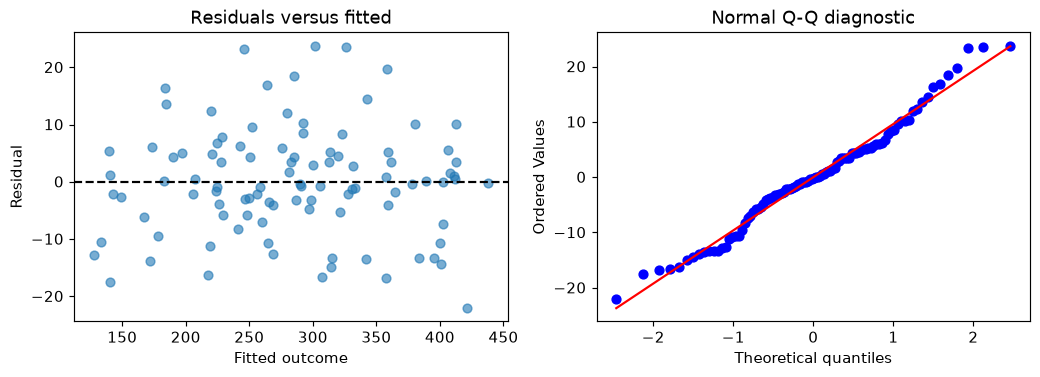

Condition number original: 423.6154119183409
With near-duplicate size: 202874.12420384865


In [5]:
fig,axes=plt.subplots(1,2,figsize=(10,3.7))
axes[0].scatter(pred,res,alpha=.6);axes[0].axhline(0,color="black",linestyle="--")
axes[0].set(title="Residuals versus fitted",xlabel="Fitted outcome",ylabel="Residual")
stats.probplot(res,dist="norm",plot=axes[1]);axes[1].set_title("Normal Q-Q diagnostic")
fig.tight_layout();plt.show()
# Demonstrate near-collinearity by design condition number, not an arbitrary verdict.
near_duplicate=size+.001*rng.normal(size=n)
print("Condition number original:",np.linalg.cond(X))
print("With near-duplicate size:",np.linalg.cond(np.column_stack([X,near_duplicate])))

## AI/ML application and interpretation

Use regression for prediction and model interpretation with held-out validation, residual diagnostics, and meaningful feature units. Separate robust prediction from causal inference. A significant coefficient can result from a large sample, leakage, or model selection; report uncertainty, practical scale, and the model/design context.

## Practice

1. Why prefer a least-squares solver over explicit normal-equation inversion?
2. Does a high training R² establish good future prediction?
3. Which assumption is violated by predictor-dependent error variance?
4. Can multicollinearity harm coefficient interpretation even with useful predictions?
5. Does normality of predictor columns establish normal regression errors?

## Solutions

1. QR/SVD are typically more numerically stable; XᵀX can worsen conditioning, and inversion fails with rank deficiency.
2. No. Evaluate on independent deployment-relevant data and compare appropriate baselines.
3. Homoscedasticity; use a suitable variance model or valid robust inference when justified.
4. Yes. Coefficients can change substantially with small perturbations because predictors contain redundant information.
5. No. Error normality concerns the conditional model, not the marginal distribution of features.

**Readiness check:** identify the estimand, independent unit, assumptions, uncertainty source, and an important failure mode before using these methods.

**Next:** [Continue studying](4_Advanced-Regression.ipynb).